In [1]:
import numpy as np
import matplotlib.pyplot as plt

**Bài 2: Logistic Regression from Scratch**

Result model with learning rate: 0.001, loss history: [np.float64(2.9215430124405266), np.float64(2.007979558569611), np.float64(1.2323233733414745), np.float64(0.8196861657084841), np.float64(0.7291037977658763), np.float64(0.711654889018951), np.float64(0.6984157344619666), np.float64(0.6916222874849385), np.float64(0.6850225974533573), np.float64(0.6788315292885819), np.float64(0.6722236283480479), np.float64(0.665696440707781), np.float64(0.6594618048982224), np.float64(0.6534783075839937), np.float64(0.6474369259298931), np.float64(0.6414490572679825), np.float64(0.6357209120511264), np.float64(0.6299701553585677), np.float64(0.6243731196627768), np.float64(0.6189369171948523), np.float64(0.6133345948664136), np.float64(0.6079999200347587), np.float64(0.6027751765464887), np.float64(0.5981971005630053), np.float64(0.5925225823661383), np.float64(0.5874021748009239), np.float64(0.5824038979026953), np.float64(0.5778458508656005), np.float64(0.5730389063539192), np.float64(0.5682327

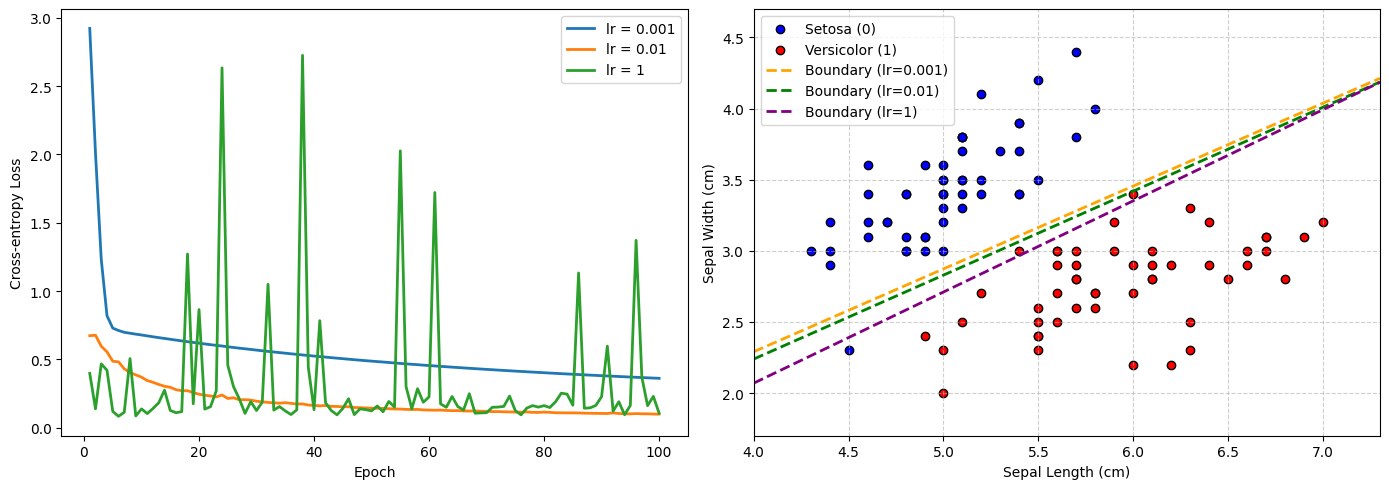

In [7]:
from sklearn.datasets import load_iris
from model.logisticRegression import LogisticRegressionScratch

# load iris dataset
iris = load_iris()
X_ = iris.data[:100, :2]
y = iris.target[:100]
N = X_.shape[0]
X = np.vstack((np.ones((1, N)), X_.T))

# train with 3 different learning rate
etas = [0.001, 0.01, 1]
max_iters = 100
models = {}

for eta in etas:
    model = LogisticRegressionScratch(eta=eta, max_iter=max_iters, tol=0)
    model.fit(X, y)
    models[eta] = model

for eta, model in models.items():
    print(f"Result model with learning rate: {eta}, loss history: {model.loss_history}")

# visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for eta, model in models.items():
    axes[0].plot(range(1, len(model.loss_history) + 1), model.loss_history, label=f'lr = {eta}', linewidth=2)

axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].set_ylabel('Cross-entropy Loss')

axes[1].scatter(X_[y == 0, 0], X_[y == 0, 1], color='blue', label='Setosa (0)', edgecolors='k')
axes[1].scatter(X_[y == 1, 0], X_[y == 1, 1], color='red', label='Versicolor (1)', edgecolors='k')

x1_vals = np.array([X_[:, 0].min() - 0.3, X_[:, 0].max() + 0.3])
colors = ['orange', 'green', 'purple']

for (eta, model), color in zip(models.items(), colors):
    w = model.w[-1].flatten()
    # Decision boundary equation: w0 + w1*x1 + w2*x2 = 0  =>  x2 = -(w0 + w1*x1) / w2
    x2_vals = -(w[0] + w[1] * x1_vals) / w[2]
    axes[1].plot(x1_vals, x2_vals, label=f'Boundary (lr={eta})', color=color, linestyle='--', linewidth=2)

axes[1].set_xlim(X_[:, 0].min() - 0.3, X_[:, 0].max() + 0.3)
axes[1].set_ylim(X_[:, 1].min() - 0.3, X_[:, 1].max() + 0.3)
axes[1].set_xlabel('Sepal Length (cm)')
axes[1].set_ylabel('Sepal Width (cm)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

#### nhận xét:
- Có thể rút ra từ đồ thị loss theo epoch, với learning rate cao mô hình có hiện tượng bị phân kỳ, gần như là dự đoán theo random
- Learning rate thấp hội tụ vói loss cao hơn so với chọn eta mức vừa nhưng cả hai đều hội tụ với độ chênh lệch epoch không đáng kể

**bài 4: Thực hành SVM**

In [9]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score

breast_cancer = load_breast_cancer()
X, y = breast_cancer.data, breast_cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=32, stratify=y
)

# preprocessing
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# SVM training
C_values = [0.1, 1, 10]
for C in C_values:
    clf_linear = SVC(kernel='linear', C=C, random_state=32)
    clf_linear.fit(X_train_scaled, y_train)
    y_pred = clf_linear.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)

    total_sv = len(clf_linear.support_)
    sv_per_class = clf_linear.n_support_
    
    print(f"{C:<8} | {total_sv:<25} | {str(sv_per_class):<25} | {acc:.4f}")


0.1      | 53                        | [27 26]                   | 0.9825
1        | 34                        | [15 19]                   | 0.9737
10       | 28                        | [14 14]                   | 0.9649


#### nhận xét:
- Tham số C càng giảm, số lương support vector nhỏ đi (accuracy cũng bị giảm nhẹ do nhiễu)
- Điều này là do C điều chỉnh sự đánh đổi của margin và penalty cho các điểm bị phân loại sai:
    + Khi C nhỏ (C = 0.1): Mô hình chấp nhận nhiều điểm bị phân loại sai để lấy margin rộng hơn
    + Khi C lớn (C = 10): Mô hình cố gắng tối thiểu hóa lượng điểm nằm trong hoặc trên margin nên khoảng cách sẽ bị hẹp hơn -> Số lượng support vectors giảm xuống, dễ bị ảnh hưởng bởi nhiễu